### 1. Import libraries


In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

### 2. Load the dataset

In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3. Clean `TotalCharges`

previously discovered `TotalCharges` contained 11 blank values stored as strings. 

In [3]:
df['TotalCharges'] = df['TotalCharges'].str.strip().replace('', np.nan)

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [4]:
print("Missing values:", df['TotalCharges'].isnull().sum())
print("Data type:", df['TotalCharges'].dtype)

Missing values: 0
Data type: float64


### 4. Prepare X and y

In [5]:
# Remove customerID from the dataset
df_model = df.drop(columns=['customerID'])

# Separate input features and target
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


### 5. Check feature types

In [6]:
X.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object

### Train-test split

Before training a machine learning model, we need to divide our dataset into two parts:
- Training data (80%) - used to teach the model.
- Testing data (20%) - used to evaluate how well the model predicts unseen customers.

I have used `stratify=y`. This is important because target is imbalanced.
- No churn: approximately 73.46%
- Churn: approximately 26.54%

Stratification preserves appropriately the same class distribution in both sets. 


In [7]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


### One-Hot Encoding

This dataset contains text categories. Most machine learning algorithms cannot directly process these text values. We need to convert them into numerical representations.

I'll use One-Hot Encoding.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical features
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify all categorical features
categorical_features = X.select_dtypes(
    include=['object', 'str']
).columns.tolist()

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15


### Create the preprocessing pipline

What is a ColumnTransformer?
A ColumnTransformer lets us apply different transformations to different columns in the same dataset.

For our project:
- Numerical columns → keep their values unchanged.
- Categorical columns → convert them using One-Hot Encoding.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

### Fit on training data and transform both sets

In [10]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


### Encode the target

In [11]:
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()

y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

print("Target classes:", target_encoder.classes_)

Target classes: ['No' 'Yes']


### Training first model - Logistic Regression

What is Logistic Regression?
Logistic Regression is a supervised machine learning algorithm used mainly for classification problems.

In this project, it predicts the probability that a customer will churn.

For example:
- Prediction probability = 0.85 → 85% estimated churn probability.
- Prediction probability = 0.15 → 15% estimated churn probability.
It is a good first model because it is relatively simple, fast and interpretable.

#### Import Logistic Regression

In [12]:
from sklearn.linear_model import LogisticRegression

#### Create and train the model

In [13]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train_processed, y_train_encoded)

c:\MyDocs\projects\customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

| **Parameter** | **Purpose** |
| --- | --- |
| max_iter=1000 | Allows enough iterations for model convergence |
| class_weight='balanced' | Gives additional weight to the minority churn class |
| random_state=42 | Supports reproducibility |


we use balanced class weights because only around 26.5% of customers churned in the dataset.

#### Make predictions

In [14]:
y_pred = logistic_model.predict(X_test_processed)

y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

### Evaluate the model

| **Metric** | **What it tells** |
| --- | --- |
| Accuracy | Overall percentage of correct predictions |
| Precision | Of customers predicted to churn, how many actually churned? |
| Recall | Of customers who actually churned, how many did we identify? |
| F1-score | Balance between precision and recall |
| ROC-AUC | How well the model distinguishes churners from non-churners |

#### Calculate evaluation metrics 

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test_encoded, y_pred))
print("Precision:", precision_score(y_test_encoded, y_pred))
print("Recall:", recall_score(y_test_encoded, y_pred))
print("F1-score:", f1_score(y_test_encoded, y_pred))
print("ROC-AUC:", roc_auc_score(y_test_encoded, y_prob))

Accuracy: 0.7381121362668559
Precision: 0.5042735042735043
Recall: 0.7887700534759359
F1-score: 0.6152241918665277
ROC-AUC: 0.8421917383554212


- Accuracy: 73.81% - Correctly predicted about 74% of customers.
- Precision: 50.43% - About half of predicted churners actually churned.
- Recall: 78.88% - Identified nearly 79% of actual churners.
- F1-score: 61.52% Balance between precision and recall
- ROC-AUC: 84.22% Good ability to distinguish churners from non-churners

Why is recall important?
Imagine the company wants to contact customers who might leave.

Your model identified 295 of the 374 customers who actually churned. It missed 79.

That means it successfully detected nearly 79% of churners, which is a useful starting point for a retention-focused system.

However, its precision is only about 50%. That means some customers flagged as high-risk would actually stay.

This trade-off matters: contacting more customers may catch more churners, but it also costs the company more.

#### Classification report

In [16]:
print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=['No Churn', 'Churn']
))

              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



#### Confusion matrix

In [17]:
cm = confusion_matrix(y_test_encoded, y_pred)

print(cm)

[[745 290]
 [ 79 295]]


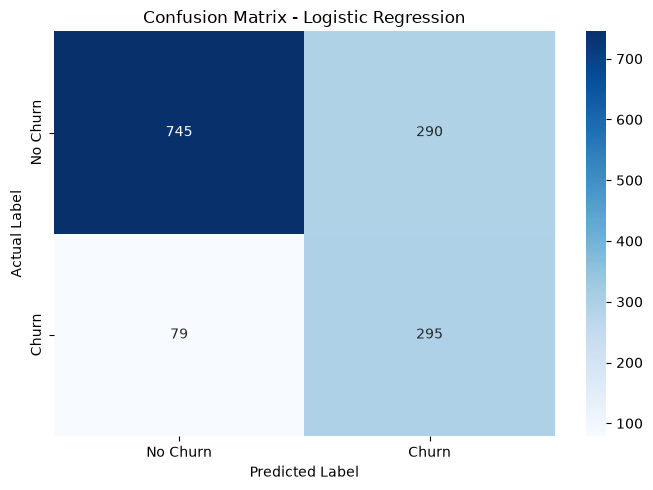

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test_encoded, y_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()

plt.savefig(
    '../outputs/logistic_regression_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


True Negative (745) - Correctly predicted customers who stayed

False Positive (290) - Predicted churn, but the customers stayed

Fake Negative (79) - Predicted stay, but the customers churned

True Positive (295) - Correctly predicted customers who churned

The **79 false negatives** are important because those are the customers the model failed to flag even though they churned.

### Logistic Regression - Initial Model Evaluation

The Logistic Regression model achieved an accuracy of 73.81%,
precision of 50.43%, recall of 78.88%, F1-score of 61.52%,
and ROC-AUC of 84.22%.

The model correctly identified 295 out of 374 customers who
churned, while missing 79 churners. However, it generated
290 false positive predictions.

The results indicate that the model has good churn detection
ability, but its precision could be improved. Therefore,
additional models will be evaluated and compared.

## Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions. It can capture complex, non-linear relationships between features and is generally more flexible than Logistic Regression.

In [19]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train_encoded)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

| **Parameter** | **Explanation** |
| --- | --- |
| n_estimators=200 | Builds 200 decision trees |
| max_depth=None | Allows trees to grow until stopping conditions are met |
| min_samples_split=2 | Minimum samples required to split a node |
| min_samples_leaf=1 | Minimum samples required in a leaf |
| class_weight='balanced' | Gives more weight to the minority churn class |
| random_state=42 | Makes results reproducible |
| n_jobs=-1 | Uses all available CPU cores |

In [20]:
# Predict churn classes
rf_y_pred = rf_model.predict(X_test_processed)

# Predict churn probabilities
rf_y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Random Forest Model Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test_encoded, rf_y_pred))
print("Precision:", precision_score(y_test_encoded, rf_y_pred))
print("Recall:", recall_score(y_test_encoded, rf_y_pred))
print("F1-score:", f1_score(y_test_encoded, rf_y_pred))
print("ROC-AUC:", roc_auc_score(y_test_encoded, rf_y_prob))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    rf_y_pred,
    target_names=target_encoder.classes_
))

Random Forest Model Performance
--------------------------------
Accuracy: 0.7707594038325053
Precision: 0.56
Recall: 0.6363636363636364
F1-score: 0.5957446808510638
ROC-AUC: 0.8229455682141104

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.82      0.84      1035
         Yes       0.56      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



**Compare Logistic Regression vs Random Forest**

| **Metric** | **Logistic Regression** | **RF** | **Better** |
| --- | --- | --- | --- | 
| Accuracy | 73.81%	| 77.08% | RF |
| Precision | 50.43% | 56.00% | RF |
| Recall | 78.88% | 63.64% | Logistic Regression |
| F1-score | 61.52%	| 59.57% | Logistic Regression |
| ROC-AUC | 84.22% | 82.29% | Logistic Regression |


For this project, the positive class (Yes) represents customers who are likely to leave.

Random Forest:
- Correctly identifies 63.64% of actual churn customers.
- When it predicts churn, 56% of those predictions are correct.
- Has higher overall accuracy than Logistic Regression.

Logistic Regression:
- Identifies 78.88% of actual churn customers.
- Has a better F1-score and ROC-AUC.
- Catches more customers who are actually going to leave.
For a customer retention business, missing a customer who is about to leave can be costly. Therefore, recall is particularly important.

My interpretation: Neither model is clearly the winner yet. Logistic Regression is currently better at detecting customers who may churn, while Random Forest is better at overall accuracy and precision.

#### Random Forest confusion matrix

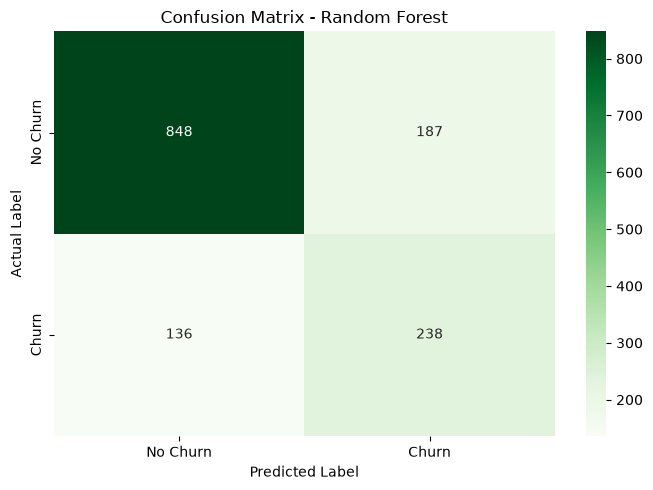

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

rf_cm = confusion_matrix(y_test_encoded, rf_y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()
plt.savefig(
    '../outputs/random_forest_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

Classification |  Logistic Regression |  Random Forest

True Negative  |  745 |     848

False Positive |  290  |   187

False Negative |  79 |  136

True Positive |   295 |     238

Logistic regression identified **295 churn customers** while random forest identified 238.

Logistic regression missed only 79 actual churn customers while random forest missed 136 actual churn customers.

Therefore, if the business wants to identify as many potential churners as possible, logistic regression currently has an advantage.

## Feature Importance Analysis - Random Forest

**Feature importance** will help us understand which customer characteristics influence random forest's predictions.

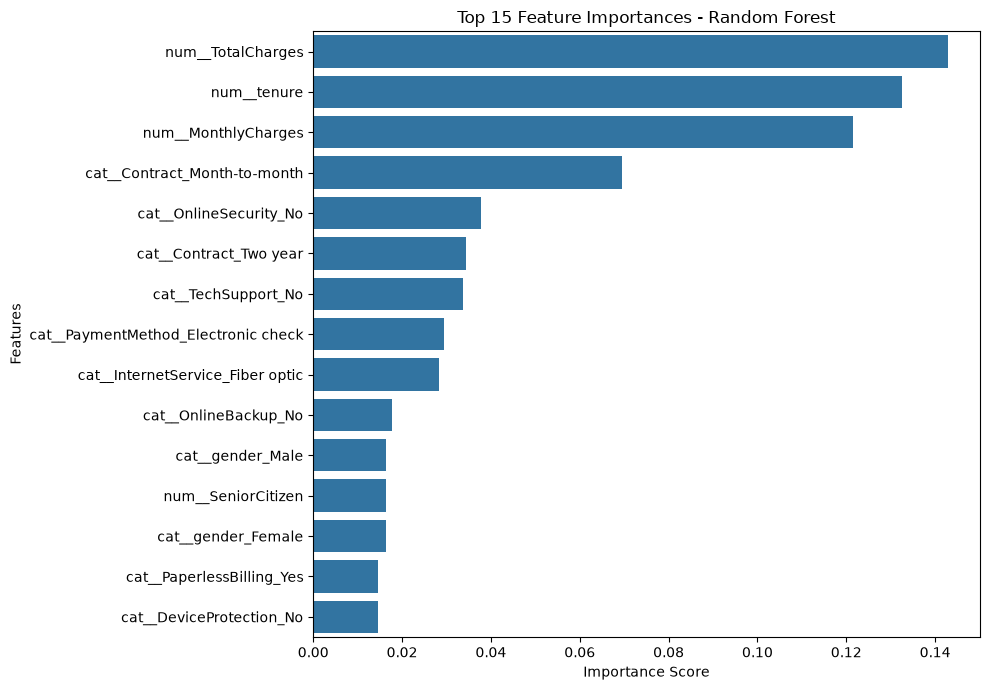

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

1. TotalCharges

This is the total amount a customer has paid over their relationship with the company.

It may help distinguish customers based on their overall spending history.

2. Tenure

This represents how long a customer has been with the company.

Customers with shorter tenure may have different churn patterns from long-term customers.

3. MonthlyCharges

This represents the customer's monthly service cost.

It may help the model identify relationships between customer spending and churn.

- TotalCharges, Tenure and MonthlyCharges are related.

For example, a customer who has stayed longer will generally have accumulated higher total charges.

Therefore, these features may contain overlapping information. Their importance scores should not be interpreted as completely independent contributions.

One limitation: feature_importances_ uses impurity-based importance. It can favour certain types of features and does not tell us whether a feature increases or decreases churn.

## Permutation Feature Importance - RF

This evaluates how much the model's performance decreases when we randomly shuffle each feature. It gives us another perspective on which features genuinely help predictions.

The idea is simple:
1. Evaluate the trained model using the original test data.
2. Randomly shuffle the values of one feature.
3. Evaluate the model again.
4. Measure how much its performance decreases.
5. Repeat this process for different features.

For this analysis, we'll use ROC-AUC as the scoring metric because it evaluates how well the model distinguishes churners from non-churners across different classification thresholds.

In [24]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
rf_permutation = permutation_importance(
    rf_model,
    X_test_processed,
    y_test_encoded,
    n_repeats=10,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

# Create a DataFrame
permutation_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance Mean': rf_permutation.importances_mean,
    'Importance Std': rf_permutation.importances_std
})

# Sort features by importance
permutation_df = permutation_df.sort_values(
    by='Importance Mean',
    ascending=False
)

# Display the top 15 features
permutation_df.head(15)

,Feature,Importance Mean,Importance Std
1,num__tenure,0.023124,0.003513
36,cat__Contract_Month-to-month,0.019992,0.003976
3,num__TotalCharges,0.011201,0.002370
38,cat__Contract_Two year,0.009298,0.001972
16,cat__InternetService_Fiber optic,0.004919,0.003410
18,cat__OnlineSecurity_No,0.001780,0.001577
0,num__SeniorCitizen,0.001373,0.001654
37,cat__Contract_One year,0.000685,0.001620
13,cat__MultipleLines_No phone service,0.000175,0.000222
23,cat__OnlineBackup_Yes,0.000004,0.001440


`n_repeats=10` - Shuffles each feature 10 times.

`random_state=42` - Ensures reproducible results.

`scoring='roc_auc'` - Measures the decrease in ROC-AUC.

`n_jobs=-1` - Uses all available CPU cores.

The results contain:
- Importance Mean: Average performance decrease after shuffling the feature.
- Importance Std: Variation in the performance decrease across repetitions.

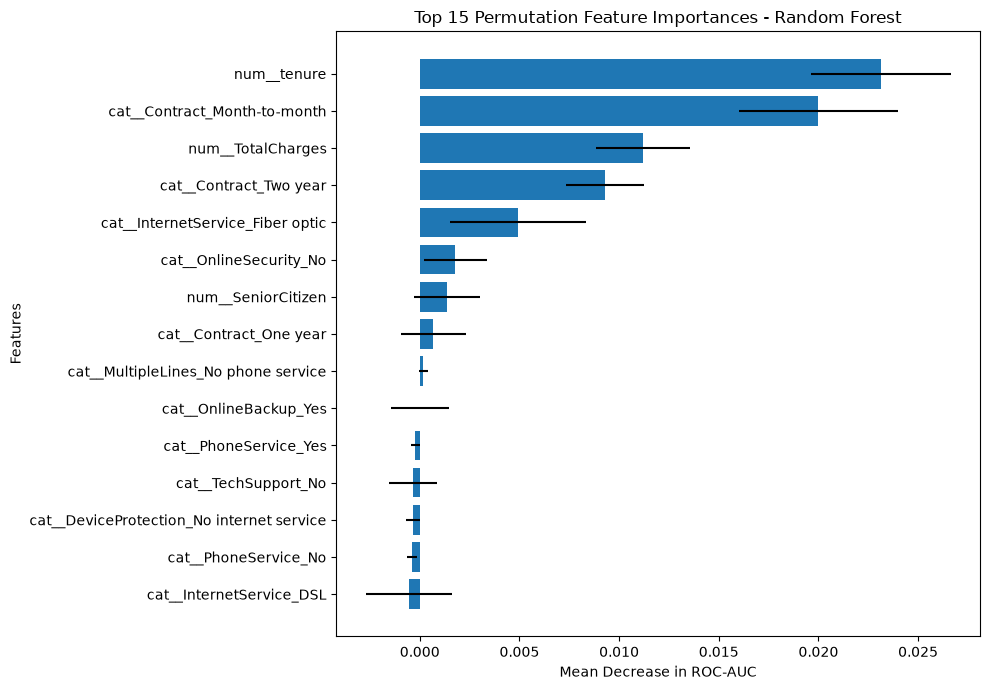

In [25]:
plt.figure(figsize=(10, 7))

top_features = permutation_df.head(15).sort_values(
    by='Importance Mean',
    ascending=True
)

plt.barh(
    top_features['Feature'],
    top_features['Importance Mean'],
    xerr=top_features['Importance Std']
)

plt.title('Top 15 Permutation Feature Importances - Random Forest')
plt.xlabel('Mean Decrease in ROC-AUC')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

## Model Performance Comparison

In [26]:
# Compare Logistic Regression and Random Forest

model_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score',
        'ROC-AUC'
    ],
    'Logistic Regression': [
        accuracy_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred),
        roc_auc_score(y_test_encoded, y_prob)
    ],
    'Random Forest': [
        accuracy_score(y_test_encoded, rf_y_pred),
        precision_score(y_test_encoded, rf_y_pred),
        recall_score(y_test_encoded, rf_y_pred),
        f1_score(y_test_encoded, rf_y_pred),
        roc_auc_score(y_test_encoded, rf_y_prob)
    ]
})

model_comparison

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.738112,0.770759
1,Precision,0.504274,0.560000
2,Recall,0.788770,0.636364
3,F1-score,0.615224,0.595745
4,ROC-AUC,0.842192,0.822946


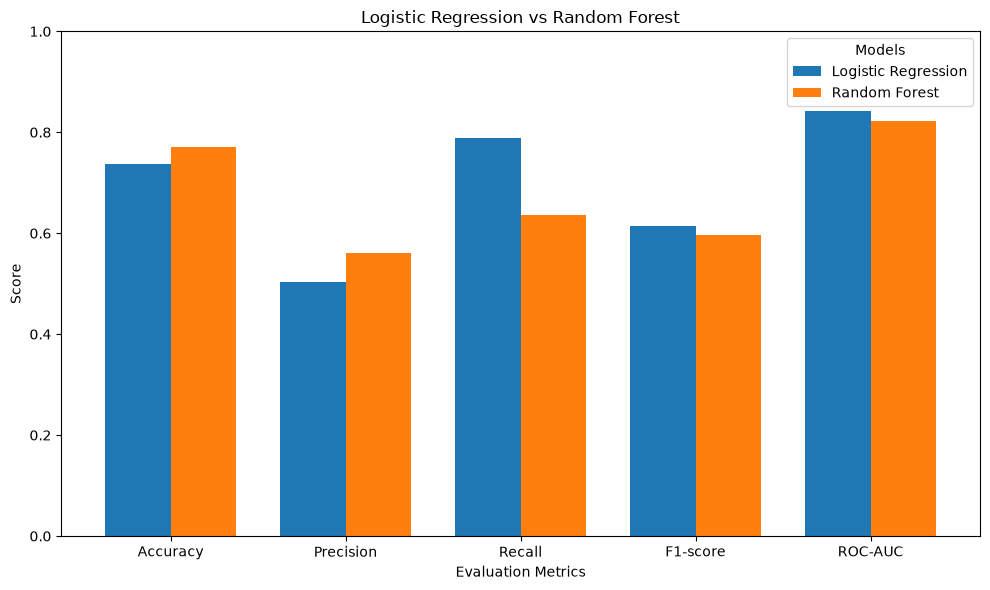

In [27]:
comparison_plot = model_comparison.set_index('Metric')

comparison_plot.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.75
)

plt.title('Logistic Regression vs Random Forest')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Models')
plt.tight_layout()
plt.show()

Logistic Regression is the stronger candidate for identifying potential churners because it has higher recall and F1-score. However, we shouldn't select the final model yet.

## Classification Threshold Tuning

we do this to see whether we can improve churn detection without unnecessarily increasing false positives.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Split the original training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Create a fresh preprocessor
validation_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit preprocessing only on the fitting data
X_fit_processed = validation_preprocessor.fit_transform(X_fit)
X_val_processed = validation_preprocessor.transform(X_val)

# Encode target labels
y_fit_encoded = target_encoder.transform(y_fit)
y_val_encoded = target_encoder.transform(y_val)

print("Training shape:", X_fit_processed.shape)
print("Validation shape:", X_val_processed.shape)

Training shape: (4507, 45)
Validation shape: (1127, 45)


### Train a Logistic Regression model for validation
We'll start with Logistic Regression because it currently has the better recall and F1-score.

In [29]:
# Train a fresh Logistic Regression model
validation_lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

validation_lr_model.fit(X_fit_processed, y_fit_encoded)

# Get churn probabilities
val_probabilities = validation_lr_model.predict_proba(
    X_val_processed
)[:, 1]

c:\MyDocs\projects\customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Evaluate different classification thresholds

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:

    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_val_encoded, val_predictions),
        'Precision': precision_score(y_val_encoded, val_predictions),
        'Recall': recall_score(y_val_encoded, val_predictions),
        'F1-score': f1_score(y_val_encoded, val_predictions)
    })

threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison.round(4)

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.30,0.6433,0.4209,0.9164,0.5768
1,0.35,0.6655,0.4361,0.8896,0.5853
2,0.40,0.7010,0.4659,0.8696,0.6068
3,0.45,0.7267,0.4911,0.8294,0.6169
4,0.50,0.7533,0.5229,0.8027,0.6332
5,0.55,0.7702,0.5485,0.7559,0.6357
6,0.60,0.7853,0.5781,0.7057,0.6355


Notice the trade-off:
- Lowering the threshold identifies more actual churners, but also increases false-positive predictions.
- Raising the threshold improves precision, but more actual churners are missed.

Which threshold should we choose?
There are two reasonable choices depending on the business objective:
- 0.45: A recall-focused option. It identifies 82.94% of actual churners, compared with 80.27% at the default 0.50 threshold.
- 0.55: An F1-focused option. It achieves the highest F1-score, 63.57%, with precision of 54.85% and recall of 75.59%.

For our customer retention project, I suggest using 0.45 as the initial candidate because identifying more customers at risk of leaving is important. This is a business-driven choice, not a claim that 0.45 is universally optimal.

These are validation results, not final test results.

### Evaluate the selected threshold on the test set

apply the selected 0.45 threshold to the original Logistic Regression model, which was trained on the full training set.

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Apply selected threshold to test probabilities
selected_threshold = 0.45

y_pred_tuned = (
    y_prob >= selected_threshold
).astype(int)

# Evaluate tuned model
print("Logistic Regression - Tuned Threshold (0.45)")
print("---------------------------------------------")

print("Accuracy:", accuracy_score(y_test_encoded, y_pred_tuned))
print("Precision:", precision_score(y_test_encoded, y_pred_tuned))
print("Recall:", recall_score(y_test_encoded, y_pred_tuned))
print("F1-score:", f1_score(y_test_encoded, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_tuned,
    target_names=target_encoder.classes_
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_tuned))

Logistic Regression - Tuned Threshold (0.45)
---------------------------------------------
Accuracy: 0.716820440028389
Precision: 0.48073959938366717
Recall: 0.8342245989304813
F1-score: 0.6099706744868035

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.67      0.78      1035
         Yes       0.48      0.83      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.69      1409
weighted avg       0.80      0.72      0.73      1409


Confusion Matrix:
[[698 337]
 [ 62 312]]


Then compare the original default threshold with the tuned threshold

In [32]:
threshold_test_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Default Threshold (0.50)': [
        accuracy_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred)
    ],
    'Tuned Threshold (0.45)': [
        accuracy_score(y_test_encoded, y_pred_tuned),
        precision_score(y_test_encoded, y_pred_tuned),
        recall_score(y_test_encoded, y_pred_tuned),
        f1_score(y_test_encoded, y_pred_tuned)
    ]
})

threshold_test_comparison.round(4)

,Metric,Default Threshold (0.50),Tuned Threshold (0.45)
0,Accuracy,0.7381,0.7168
1,Precision,0.5043,0.4807
2,Recall,0.7888,0.8342
3,F1-score,0.6152,0.6100


The most important improvement is recall.  The tuned model now identifies 83.42% of actual churn customers, compared with 78.88% using the default threshold.

For this project, I would retain Logistic Regression with threshold 0.45 as a recall-focused candidate model.

However, we shouldn't claim it is definitively the best model yet:
- Random Forest achieved higher accuracy.
- Logistic Regression at 0.45 achieved higher recall.
- Logistic Regression at 0.50 achieved a slightly higher F1-score than the tuned version.
The final choice should consider the cost of contacting customers unnecessarily versus the cost of losing customers.

### Threshold Tuning - Conclusion

Classification threshold tuning was performed using a validation dataset
to improve the identification of potential churn customers.

The threshold was adjusted from the default 0.50 to 0.45.

On the unseen test dataset, the tuned Logistic Regression model achieved
83.42% recall, compared with 78.88% at the default threshold.

Although accuracy and precision decreased slightly, the model identified
more actual churn customers and reduced false negatives from 79 to 62.

Therefore, the 0.45 threshold is considered a recall-focused candidate
for the customer retention objective.

## Hyperparameter Tuning

Finds better model settings to improve model performance.

For example, in Random Forest:
- n_estimators: Number of decision trees in the forest.
- max_depth: Maximum depth of each tree.
- min_samples_split: Minimum number of samples needed to split a node.
- min_samples_leaf: Minimum number of samples required in a leaf node.

These settings are called hyperparameters because we choose them before training the model.

**Why do we need cross-validation?**
Instead of testing a model configuration using just one train-validation split, we can use 5-fold cross-validation.

The training data is divided into five parts. The model trains on four parts and validates on the remaining part. This process repeats five times.

This gives us a more reliable estimate of model performance.

Important: We will use only X_train and y_train for hyperparameter tuning. Our X_test and y_test will remain untouched until final evaluation.

**Start with Logistic Regression**

We'll use GridSearchCV to test different values of C.

C controls the strength of regularization:
- Smaller C → stronger regularization.
- Larger C → weaker regularization.

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression

# Create a pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Define hyperparameter values
lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Set up GridSearchCV
lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

because the existing preprocessor was fitted earlier on the full training set, we'll create a fresh, unfitted preprocessor for this pipeline. That ensures preprocessing is learned separately inside each cross-validation fold.



In [34]:
lr_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

lr_pipeline = Pipeline([
    ('preprocessor', lr_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [35]:
lr_grid_search.fit(X_train, y_train_encoded)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


c:\MyDocs\projects\customer-churn-prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see h

The output shows:

Best C = 10

Best cross-validation ROC-AUC = 0.8458 (84.58%)

This means among the five c values we tested, C=10 achieved the best average ROC-AUC across the five validation folds.
It doesn't mean C=10 is universally best. It is best among the candidates we tested.


**ConvergenceWarning**

warning says:

lbfgs failed to converge after 1000 iteration(s)

In simple terms, Logistic Regression was still trying to find its optimal model coefficients when it reached the maximum of 1,000 iterations.

One likely reason is that your numerical features have very different scales.

For example:
- SeniorCitizen: 0 or 1
- tenure: 0–72
- MonthlyCharges: approximately 18–119
- TotalCharges: can reach thousands
We should scale numerical features before training Logistic Regression.

Let's fix this before interpreting the tuning results.

In [36]:
from sklearn.preprocessing import StandardScaler

lr_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

lr_pipeline = Pipeline([
    ('preprocessor', lr_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=3000,
        class_weight='balanced',
        random_state=42
    ))
])

In [37]:
lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

In [38]:
lr_grid_search.fit(X_train, y_train_encoded)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see h

In [39]:
print("Best Parameters:", lr_grid_search.best_params_)
print("Best Cross-Validation ROC-AUC:", lr_grid_search.best_score_)

Best Parameters: {'classifier__C': 10}
Best Cross-Validation ROC-AUC: 0.8462193813010874


Best C = 10: Among the five values tested (0.01, 0.1, 1, 10, 100), C=10 achieved the highest average cross-validation ROC-AUC.



ROC-AUC = 0.8462: The tuned model has good ability to distinguish between customers who churn and those who do not.



5-fold cross-validation: The training data was divided into five parts. The model was trained and evaluated across five different combinations, and the score is the average.

### Logistic Regression - Hyperparameter Tuning

GridSearchCV with 5-fold Stratified Cross-Validation was used
to identify the best regularization parameter (C).

**Best Parameters:** C = 10

**Best Cross-Validation ROC-AUC:** 0.8462

The tuned Logistic Regression model achieved an average ROC-AUC
of 84.62% across the five validation folds.

### Evaluate the tuned logistic regression model

In [40]:
# Get the best tuned model
best_lr_model = lr_grid_search.best_estimator_

# Make predictions on the test dataset
y_pred_tuned_lr = best_lr_model.predict(X_test)
y_prob_tuned_lr = best_lr_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Tuned Logistic Regression Results")
print("----------------------------------")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_tuned_lr))
print("Precision:", precision_score(y_test_encoded, y_pred_tuned_lr))
print("Recall:", recall_score(y_test_encoded, y_pred_tuned_lr))
print("F1-score:", f1_score(y_test_encoded, y_pred_tuned_lr))
print("ROC-AUC:", roc_auc_score(y_test_encoded, y_prob_tuned_lr))

Tuned Logistic Regression Results
----------------------------------
Accuracy: 0.7395315826827538
Precision: 0.5060449050086355
Recall: 0.7834224598930482
F1-score: 0.614900314795383
ROC-AUC: 0.840649461365574


In [41]:
# Compare Baseline and Tuned Logistic Regression

lr_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Baseline Logistic Regression': [
        accuracy_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred),
        roc_auc_score(y_test_encoded, y_prob)
    ],
    'Tuned Logistic Regression': [
        accuracy_score(y_test_encoded, y_pred_tuned_lr),
        precision_score(y_test_encoded, y_pred_tuned_lr),
        recall_score(y_test_encoded, y_pred_tuned_lr),
        f1_score(y_test_encoded, y_pred_tuned_lr),
        roc_auc_score(y_test_encoded, y_prob_tuned_lr)
    ]
})

# Display the comparison table
lr_comparison.set_index('Metric').style.format('{:.4f}').highlight_max(
    axis=1, color='lightgreen'
)

,Baseline Logistic Regression,Tuned Logistic Regression
Metric,,
Accuracy,0.7381,0.7395
Precision,0.5043,0.5060
Recall,0.7888,0.7834
F1-score,0.6152,0.6149
ROC-AUC,0.8422,0.8406


### Logistic Regression - Hyperparameter Tuning Conclusion

GridSearchCV identified C = 10 as the best hyperparameter,
with a cross-validation ROC-AUC of 0.8462.

The tuned model achieved a test ROC-AUC of 0.8406.

Compared with the baseline model, the tuned model showed
only marginal changes in performance. The baseline achieved
slightly higher recall, F1-score and ROC-AUC, while the tuned
model achieved slightly higher accuracy and precision.

Therefore, hyperparameter tuning did not produce a significant
performance improvement for Logistic Regression.

## Random Forest hyperparameter tuning 

use the same approach as Logistic Regression: GridSearchCV + 5-fold Stratified Cross-Validation.

Define the Random Forest pipeline


Including the existing preprocessing inside the pipeline to prevent data leakage during cross-validation.

In [42]:
# Create the preprocessing pipeline

rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Create the Random Forest pipeline

rf_pipeline = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

Why don't we use StandardScaler here?

Unlike Logistic Regression, Random Forest does not generally require numerical feature scaling because decision trees split based on feature values rather than distances or gradient-based optimization.

Define the random forest hyperparameter grid

In [43]:
# Define hyperparameter grid

rf_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

configure GridSearchCV


In [44]:
# Define Stratified 5-Fold Cross-Validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=rf_cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

estimator: The Random Forest pipeline we created.



param_grid: The 81 parameter combinations.



cv=rf_cv: Evaluates each combination using 5-fold cross-validation.



scoring='roc_auc': Selects the model with the highest average ROC-AUC.



n_jobs=-1: Uses available CPU cores to speed up execution.



verbose=1: Displays progress information.

Run hyperparameter tuning

In [45]:
# Perform hyperparameter tuning
rf_grid_search.fit(X_train, y_train_encoded)

# Display best results
print("Best Parameters:", rf_grid_search.best_params_)
print("Best Cross-Validation ROC-AUC:", rf_grid_search.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 300}
Best Cross-Validation ROC-AUC: 0.8465576215503642


n_estimators = 300: The best-performing configuration used 300 decision trees.



max_depth = 10: Each tree is limited to a maximum depth of 10, helping control model complexity.



min_samples_split = 10: A node needs at least 10 samples before it can be split.



min_samples_leaf = 4: Each leaf must contain at least 4 samples.

### Random Forest - Hyperparameter Tuning

GridSearchCV with 5-fold Stratified Cross-Validation was
used to identify the optimal Random Forest hyperparameters.

**Best Parameters:**
- n_estimators: 300
- max_depth: 10
- min_samples_split: 10
- min_samples_leaf: 4

**Best Cross-Validation ROC-AUC:** 0.8466

The best configuration achieved an average ROC-AUC of
84.66% across the five cross-validation folds.

### Evaluate the tuned RF

In [46]:
# Get the best tuned Random Forest model
best_rf_model = rf_grid_search.best_estimator_

# Make predictions
rf_tuned_y_pred = best_rf_model.predict(X_test)
rf_tuned_y_prob = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Tuned Random Forest Results")
print("----------------------------------")
print("Accuracy:", accuracy_score(y_test_encoded, rf_tuned_y_pred))
print("Precision:", precision_score(y_test_encoded, rf_tuned_y_pred))
print("Recall:", recall_score(y_test_encoded, rf_tuned_y_pred))
print("F1-score:", f1_score(y_test_encoded, rf_tuned_y_pred))
print("ROC-AUC:", roc_auc_score(y_test_encoded, rf_tuned_y_prob))

Tuned Random Forest Results
----------------------------------
Accuracy: 0.7530163236337828
Precision: 0.5236363636363637
Recall: 0.7700534759358288
F1-score: 0.6233766233766234
ROC-AUC: 0.8420121935467204


Model performance comparison

In [47]:
# Compare Baseline and Tuned Random Forest

rf_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Baseline Random Forest': [
        accuracy_score(y_test_encoded, rf_y_pred),
        precision_score(y_test_encoded, rf_y_pred),
        recall_score(y_test_encoded, rf_y_pred),
        f1_score(y_test_encoded, rf_y_pred),
        roc_auc_score(y_test_encoded, rf_y_prob)
    ],
    'Tuned Random Forest': [
        accuracy_score(y_test_encoded, rf_tuned_y_pred),
        precision_score(y_test_encoded, rf_tuned_y_pred),
        recall_score(y_test_encoded, rf_tuned_y_pred),
        f1_score(y_test_encoded, rf_tuned_y_pred),
        roc_auc_score(y_test_encoded, rf_tuned_y_prob)
    ]
})

# Display comparison table
rf_comparison.set_index('Metric').style.format('{:.4f}').highlight_max(
    axis=1, color='lightgreen'
)

,Baseline Random Forest,Tuned Random Forest
Metric,,
Accuracy,0.7708,0.7530
Precision,0.5600,0.5236
Recall,0.6364,0.7701
F1-score,0.5957,0.6234
ROC-AUC,0.8229,0.8420


This is an interesting result!
- Accuracy decreased: From 77.08% to 75.30%.
- Precision decreased: From 56.00% to 52.36%.
- Recall improved: From 63.64% to 77.01%.
- F1-score improved: From 59.57% to 62.34%.
- ROC-AUC improved: From 82.29% to 84.20%.
The tuned model identifies more actual churn customers than the baseline Random Forest.

For customer retention objective, this is valuable because missing a customer who is about to leave could mean losing an opportunity to retain them.

However, the lower precision means more customers predicted as churners will actually stay.

### Random Forest - Hyperparameter Tuning Conclusion

GridSearchCV identified the optimal hyperparameters with
a cross-validation ROC-AUC of 0.8466.

The tuned Random Forest model achieved a test ROC-AUC of
0.8420, compared with 0.8229 for the baseline model.

The tuned model improved recall from 63.64% to 77.01%
and F1-score from 59.57% to 62.34%.

However, accuracy decreased from 77.08% to 75.30%,
and precision decreased from 56.00% to 52.36%.

Overall, hyperparameter tuning improved the model's ability
to identify potential churn customers, although it also
increased false positive predictions.

## Model performance comparison

In [48]:
# Compare all four models

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression (Baseline)',
        'Logistic Regression (Tuned)',
        'Random Forest (Baseline)',
        'Random Forest (Tuned)'
    ],
    'Accuracy': [
        accuracy_score(y_test_encoded, y_pred),
        accuracy_score(y_test_encoded, y_pred_tuned_lr),
        accuracy_score(y_test_encoded, rf_y_pred),
        accuracy_score(y_test_encoded, rf_tuned_y_pred)
    ],
    'Precision': [
        precision_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred_tuned_lr),
        precision_score(y_test_encoded, rf_y_pred),
        precision_score(y_test_encoded, rf_tuned_y_pred)
    ],
    'Recall': [
        recall_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred_tuned_lr),
        recall_score(y_test_encoded, rf_y_pred),
        recall_score(y_test_encoded, rf_tuned_y_pred)
    ],
    'F1-score': [
        f1_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred_tuned_lr),
        f1_score(y_test_encoded, rf_y_pred),
        f1_score(y_test_encoded, rf_tuned_y_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test_encoded, y_prob),
        roc_auc_score(y_test_encoded, y_prob_tuned_lr),
        roc_auc_score(y_test_encoded, rf_y_prob),
        roc_auc_score(y_test_encoded, rf_tuned_y_prob)
    ]
})

# Display the comparison table
model_comparison.set_index('Model').style.format('{:.4f}').highlight_max(
    axis=0, color='lightgreen'
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (Baseline),0.7381,0.5043,0.7888,0.6152,0.8422
Logistic Regression (Tuned),0.7395,0.5060,0.7834,0.6149,0.8406
Random Forest (Baseline),0.7708,0.5600,0.6364,0.5957,0.8229
Random Forest (Tuned),0.7530,0.5236,0.7701,0.6234,0.8420


### Overall Model Comparison - Observations

The four models demonstrated different strengths across
the evaluation metrics.

- Baseline Random Forest achieved the highest accuracy (77.08%)
  and precision (56.00%).
- Baseline Logistic Regression achieved the highest recall
  (78.88%) and ROC-AUC (84.22%).
- Tuned Random Forest achieved the highest F1-score (62.34%).
- Hyperparameter tuning produced only marginal changes
  in Logistic Regression performance.

Overall, the models demonstrate different trade-offs between
identifying churn customers and minimizing false-positive
predictions. Therefore, final model selection should consider
the customer retention objective rather than accuracy alone.

**I'd choose Baseline logistic regression and tuned random forest.**

**- Baseline logistic regression - best recall and roc-auc**

Highest recall (78.88%): It identifies the highest proportion of actual churn customers among the four models.



Highest ROC-AUC (84.22%): It has the strongest ability to distinguish churn customers from non-churn customers across different classification thresholds.

**- Tuned RF - Best F1-score**

F1-score balances precision and recall. Therefore, this model offers a slightly better balance between identifying churners and avoiding false alarms.

**- why not the other two**

Baseline RF - Highest accuracy and precision, but considerably lower recall (63.64%).

Tuned Logistic Regression -	Very similar to baseline Logistic Regression, without meaningful overall improvement.

## Confusion Matrix Analysis

### Visualise both confusion matrices

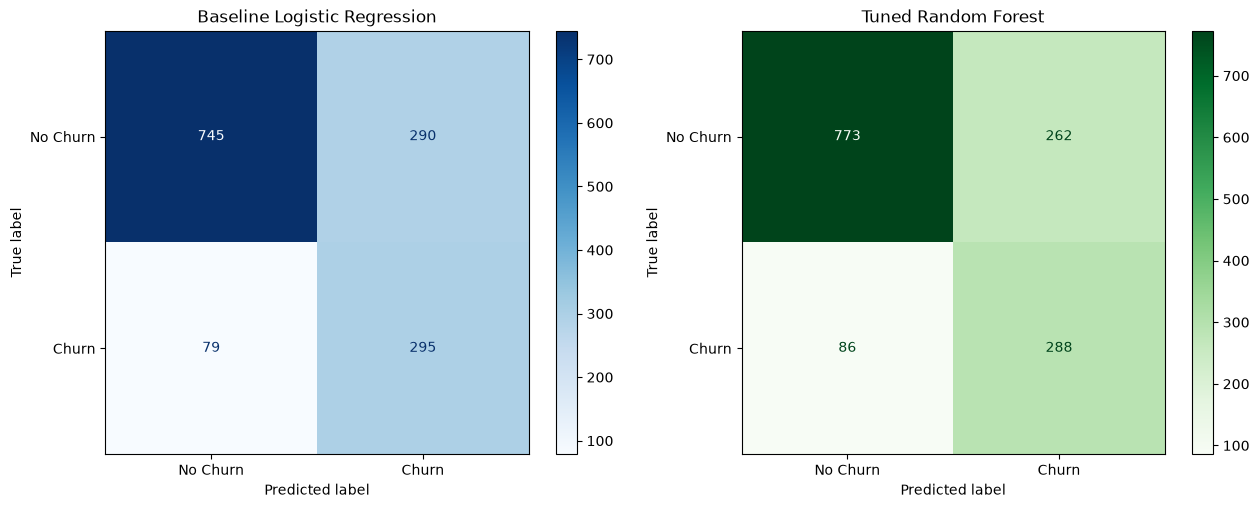

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Baseline Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    y_pred,
    display_labels=['No Churn', 'Churn'],
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Baseline Logistic Regression')

# Tuned Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test_encoded,
    rf_tuned_y_pred,
    display_labels=['No Churn', 'Churn'],
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title('Tuned Random Forest')

plt.tight_layout()
plt.show()

Confusion matrix structure
| |	Predicted No Churn |	Predicted Churn |
| --- | --- | --- |
| Actual No Churn |	TN |	FP |
| Actual Churn |	FN |	TP |

TN = True Negative · FP = False Positive · FN = False Negative · TP = True Positive

| Result | Logistic regression | Tuned Random Forest |
| --- | --- | --- |
| TN | 745 | 773 |
| FP | 290 | 262 |
| FN | 79 | 86 |
| TP | 295 | 288 |

Baseline logistic regression:

- correctly identified 295 customers who churned.
- Missed 79 actual churners.
- Incorrectly identified 290 customers who stayed.

Tuned random forest:
- correctly identified 288 customers who churned.
- Missed 86 actual churners.
- Incorrectly identified 262 customers who stayed.

### Confusion Matrix Analysis

The confusion matrices were used to compare the prediction
performance of Baseline Logistic Regression and Tuned
Random Forest.

Baseline Logistic Regression correctly identified 295
churn customers and missed 79 actual churners.

Tuned Random Forest correctly identified 288 churn
customers and missed 86 actual churners.

Although Tuned Random Forest produced fewer false positives
(262 compared with 290), Baseline Logistic Regression
identified more actual churn customers.

Therefore, Baseline Logistic Regression showed an advantage
for the customer retention objective at the default threshold.

### ROC Curve Analysis

ROC stands for **Receiver Operating Characteristic.**

It is a graph that shows how well a classification model distinguishes between two classes.

- Customers who will churn. 
- Customers who will not churn.

It uses 2 measurements:

- **True Positive Rate (TPR)** - how many actual churners the model correctly identifies.

- **False Positive Rate (FPR)** - how many customers who would stay are incorrectly classified as churners.

The ROC curve shows the trade-off between those two measurements at different classification thresholds.

**AUC (Area Under the Curve)**

AUC measures the overall ability of the model to distinguish between the two classes.

AUC value |	General interpretation

0.90–1.00	Excellent

0.80–0.90	Good

0.70–0.80	Fair

0.60–0.70	Poor

0.50	No better than random ranking

ROC curves


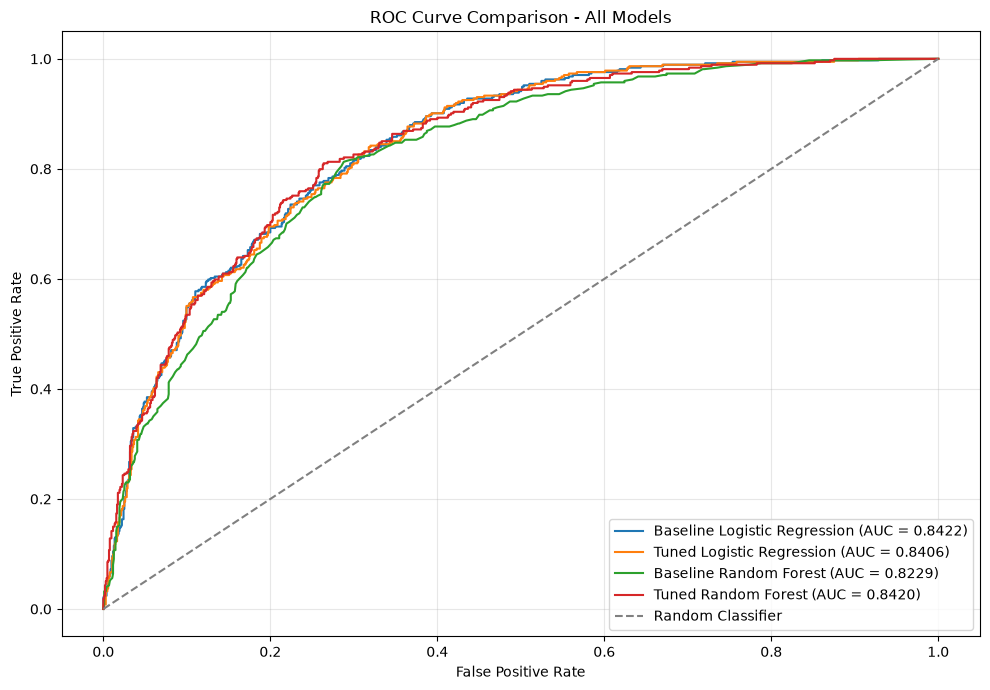

In [50]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Store model probabilities
models = {
    'Baseline Logistic Regression': y_prob,
    'Tuned Logistic Regression': y_prob_tuned_lr,
    'Baseline Random Forest': rf_y_prob,
    'Tuned Random Forest': rf_tuned_y_prob
}

# Plot ROC curves
plt.figure(figsize=(10, 7))

for model_name, probabilities in models.items():

    fpr, tpr, thresholds = roc_curve(
        y_test_encoded,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test_encoded,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc_score:.4f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - All Models')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Best ROC-AUC - Baseline Logistic Regression (0.8422)

All curves are above the diagonal reference line. This means all four models have learned to distinguish between churn and non-churn customers better than random guessing.

Tuned Random Forest is very close. Its ROC-AUC is 0.8420, almost identical to baseline Logistic Regression.

Notice how close the four curves are?

This tells us that hyperparameter tuning did not create a major improvement in the models' overall ability to distinguish between churners and non-churners.

Also, ROC-AUC evaluates ranking ability across thresholds. It does not tell us which model produces the best predictions at the default 0.50 threshold.

## Final Model Selection

Baseline Logistic Regression (0.50 threshold)



Threshold-tuned Logistic Regression (0.45 threshold)



Tuned Logistic Regression (0.50 threshold)



Baseline Random Forest (0.50 threshold)



Tuned Random Forest (0.50 threshold)

In [51]:
# Final model comparison including threshold tuning

final_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression (Baseline)',
        'Logistic Regression (Threshold 0.45)',
        'Logistic Regression (Tuned)',
        'Random Forest (Baseline)',
        'Random Forest (Tuned)'
    ],

    'Accuracy': [
        accuracy_score(y_test_encoded, y_pred),
        accuracy_score(y_test_encoded, y_pred_tuned),
        accuracy_score(y_test_encoded, y_pred_tuned_lr),
        accuracy_score(y_test_encoded, rf_y_pred),
        accuracy_score(y_test_encoded, rf_tuned_y_pred)
    ],

    'Precision': [
        precision_score(y_test_encoded, y_pred),
        precision_score(y_test_encoded, y_pred_tuned),
        precision_score(y_test_encoded, y_pred_tuned_lr),
        precision_score(y_test_encoded, rf_y_pred),
        precision_score(y_test_encoded, rf_tuned_y_pred)
    ],

    'Recall': [
        recall_score(y_test_encoded, y_pred),
        recall_score(y_test_encoded, y_pred_tuned),
        recall_score(y_test_encoded, y_pred_tuned_lr),
        recall_score(y_test_encoded, rf_y_pred),
        recall_score(y_test_encoded, rf_tuned_y_pred)
    ],

    'F1-score': [
        f1_score(y_test_encoded, y_pred),
        f1_score(y_test_encoded, y_pred_tuned),
        f1_score(y_test_encoded, y_pred_tuned_lr),
        f1_score(y_test_encoded, rf_y_pred),
        f1_score(y_test_encoded, rf_tuned_y_pred)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test_encoded, y_prob),
        roc_auc_score(y_test_encoded, y_prob),
        roc_auc_score(y_test_encoded, y_prob_tuned_lr),
        roc_auc_score(y_test_encoded, rf_y_prob),
        roc_auc_score(y_test_encoded, rf_tuned_y_prob)
    ]
})

final_comparison.set_index('Model').style.format('{:.4f}')

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (Baseline),0.7381,0.5043,0.7888,0.6152,0.8422
Logistic Regression (Threshold 0.45),0.7168,0.4807,0.8342,0.6100,0.8422
Logistic Regression (Tuned),0.7395,0.5060,0.7834,0.6149,0.8406
Random Forest (Baseline),0.7708,0.5600,0.6364,0.5957,0.8229
Random Forest (Tuned),0.7530,0.5236,0.7701,0.6234,0.8420


accuracy - RF (baseline)

precision - RF (baseline)

recall - LR - threshold 0.45

f1-score - RF tuned

roc-auc - LR baseline

objective of the project: Predict customers who are likely to leave the company so that the company can take early customer retention actions.

for this objective, missing an actual churn customer (false negative) can be costly.

| Metric | LR Baseline | LR Threshold 0.45 |
| --- | --- | --- |
| Accuracy | 0.7381	| 0.7168 |
| Precision | 0.5043 | 0.4807
| Recall |	0.7888	| **0.8342**
| F1-score | 0.6152	 | 0.6100
| ROC-AUC | 0.8422 | 0.8422
| False Negatives | 79 | **62**

The threshold 0.45 configuration identifies 17 additional actual churners, but produces 47 additional false positives.

**Recommended candidate:**
 **Baseline Logistic Regression with a 0.45 classification threshold.**


### Final Model Selection

Five prediction configurations were compared using
Accuracy, Precision, Recall, F1-score and ROC-AUC.

Baseline Random Forest achieved the highest accuracy
(77.08%) and precision (56.00%).

Tuned Random Forest achieved the highest F1-score
(62.34%).

However, Logistic Regression with a classification
threshold of 0.45 achieved the highest recall of
83.42%, identifying more actual churn customers.

Compared with the default Logistic Regression threshold
of 0.50, the 0.45 threshold reduced false negatives
from 79 to 62.

Since the primary objective of this project is to identify
potential churn customers and support customer retention
activities, Baseline Logistic Regression with a 0.45
classification threshold was selected as the preferred
candidate for further development.

This selection prioritizes recall while acknowledging
the trade-off of increased false-positive predictions.

## Model Explainability using SHAP (Explainability AI)

We'll investigate:
- Which customer characteristics influence churn predictions?
- Why does the model predict that a particular customer may churn?
- Which features have the greatest influence on predictions?

**What is SHAP?**

SHAP stands for SHapley Additive exPlanations.

It is a technique used to explain machine learning predictions by estimating how much each feature contributes to a prediction.

Logistic Regression model can predict that a customer is likely to churn, but that prediction alone doesn't tell us why.

For example:
This customer has a high probability of churning.

That's useful, but a business would also want to know:
- Is it because the customer has a month-to-month contract?
- Is it because they have been a customer for a short period?
- Are their monthly charges relatively high?
- Do they lack technical support or online security services?

SHAP helps us investigate these questions.

**Install and import SHAP**

In [54]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


**Prepare the model for SHAP**

We selected Baseline Logistic Regression with a 0.45 classification threshold. However, SHAP explains the underlying model's prediction scores, not the threshold itself. The threshold only changes how those scores are converted into Churn/No Churn labels.

Baseline Logistic Regression was trained using preprocessed data (X_train_processed), so we need to give SHAP data in the same format.

**Check the processed features**

In [55]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nFeature names:")
print(feature_names)

Number of features: 45
Processed training shape: (5634, 45)
Processed test shape: (1409, 45)

Feature names:
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Female' 'cat__gender_Male'
 'cat__Partner_No' 'cat__Partner_Yes' 'cat__Dependents_No'
 'cat__Dependents_Yes' 'cat__PhoneService_No' 'cat__PhoneService_Yes'
 'cat__MultipleLines_No' 'cat__MultipleLines_No phone service'
 'cat__MultipleLines_Yes' 'cat__InternetService_DSL'
 'cat__InternetService_Fiber optic' 'cat__InternetService_No'
 'cat__OnlineSecurity_No' 'cat__OnlineSecurity_No internet service'
 'cat__OnlineSecurity_Yes' 'cat__OnlineBackup_No'
 'cat__OnlineBackup_No internet service' 'cat__OnlineBackup_Yes'
 'cat__DeviceProtection_No' 'cat__DeviceProtection_No internet service'
 'cat__DeviceProtection_Yes' 'cat__TechSupport_No'
 'cat__TechSupport_No internet service' 'cat__TechSupport_Yes'
 'cat__StreamingTV_No' 'cat__StreamingTV_No internet service'
 'cat__StreamingTV_Yes' 'cat__Stre

**Create the SHAP Explainer**

In [56]:
# Create a background dataset for SHAP
shap_background = X_train_processed

# Create SHAP explainer for Logistic Regression
shap_explainer = shap.LinearExplainer(
    logistic_model,
    shap_background
)

print("SHAP explainer created successfully!")

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


SHAP explainer created successfully!


1. shap_background

SHAP needs a reference dataset to understand what a typical prediction looks like. We are using your training data as the background reference.

2. shap.LinearExplainer()

This creates an explainer designed for linear models. It will use the learned coefficients and feature values to calculate how the different features contribute to each prediction.

3. logistic_model

We are using your original baseline Logistic Regression model, not the tuned Logistic Regression model, because our selected candidate at this stage is the baseline model with a 0.45 threshold.

**Calculate SHAP values**

In [57]:
# Select a random sample of 500 customers from the test set
rng = np.random.default_rng(42)

shap_indices = rng.choice(
    X_test_processed.shape[0],
    size=500,
    replace=False
)

X_shap = X_test_processed[shap_indices]

# Calculate SHAP values
shap_values = shap_explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.shape)

SHAP values calculated successfully!
SHAP values shape: (500, 45)


**Global feature importance (SHAP)**

This visualisation will identify which features have the greatest overall influence on the model's churn predictions.

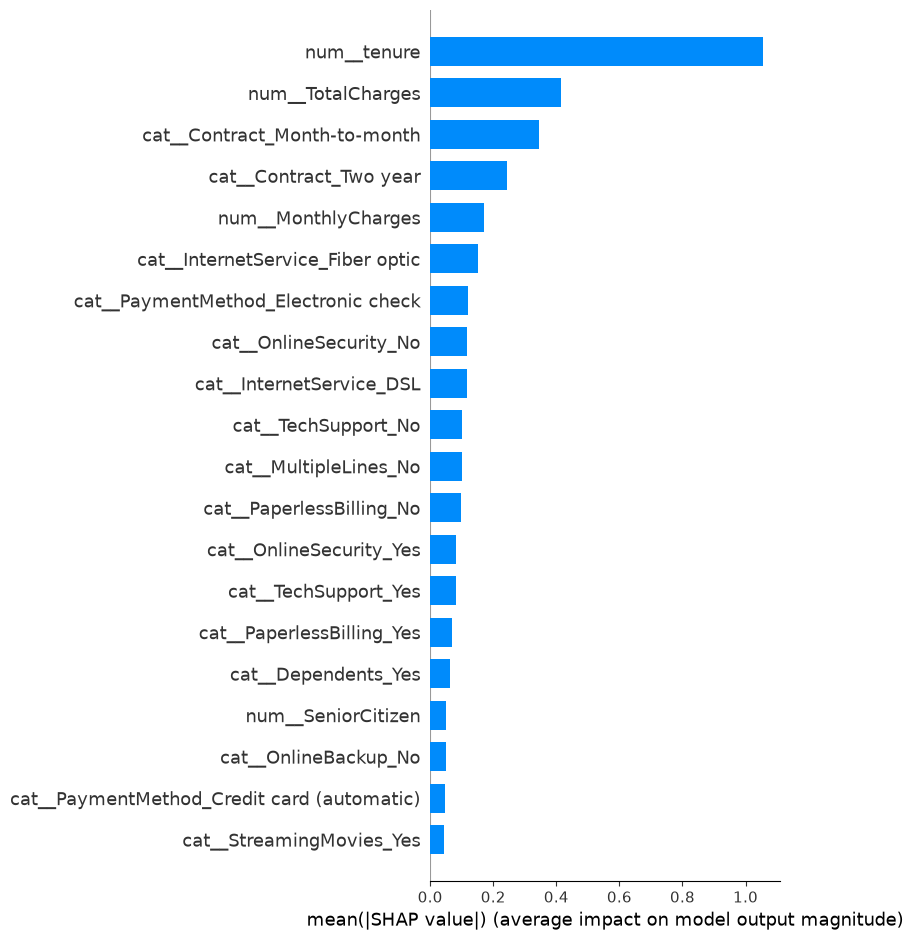

In [58]:
# Global SHAP feature importance
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar"
)

Key observations
1. Tenure is the strongest feature by a considerable margin.

This suggests that the length of a customer's relationship with the company has the greatest overall influence on the model's predictions.

2. TotalCharges is the second most influential feature.

This is understandable because total charges are related to how long a customer has stayed and how much they pay.

3. Contract type has a strong influence.

Both month-to-month and two-year contracts appear among the top features. This indicates that contract arrangements are important to the model's predictions.

4. MonthlyCharges also matters.

The amount customers pay each month contributes to the model's predictions, although its overall influence is smaller than tenure and total charges.

### SHAP Global Feature Importance

The SHAP summary bar plot was used to identify the features that have the greatest overall influence on the Logistic Regression model's predictions.

The results show that **tenure** is the most influential feature, followed by **TotalCharges**, **Contract_Month-to-month**, **Contract_Two year**, and **MonthlyCharges**.

These findings suggest that customer relationship duration, billing information, and contract type play important roles in the model's churn predictions.

However, this visualization represents the average magnitude of feature contributions and does not indicate whether a feature increases or decreases the predicted likelihood of churn. Further analysis using a SHAP beeswarm plot is required to understand the direction of these contributions.